In [ ]:
import os

import pandas as pd
import numpy as np
from ot import sliced_wasserstein_distance
import random
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
from cluster_weather_years.functions import (
    build_df_centroids,
    build_df_random,
)
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    HYDROLOGICAL_YEARS,
    COUNTRIES,
)
from sa_settings import MATCH_COUNTRIES, NUM_CLUSTERS

In [66]:
# Config
NUM_CLUSTERS = 5  # hardcode
NUM_CLUSTERS_LARGE_SMALL = 30  # hardcode, 30 years if main one is 5y and vice versa

# RUN_ID = "NL_20251003_1321"  # NL, 30 years
RUN_ID = "NL_20251023_0942"  # NL, 5 years
RUN_ID_alternative = "BE_20251001_1623"  # BE

RUN_ID_LARGE_SMALL = "NL_20251024_1320"  # 30 years if main one is 5y and vice versa

seed = 42
random.seed(seed)

# 1. Build dataframes

In [68]:
# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

vars_to_match = []
for country in MATCH_COUNTRIES:
    vars_to_match.extend(
        [
            f"{country}_OFF_prod",
            f"{country}_ON_prod",
            f"{country}_SOLAR_prod",
            f"{country}_Demand",
        ]
    )

vars_to_plot = vars_to_match + [f"{country} Multi RMSE" for country in MATCH_COUNTRIES]

all_vars = df_daily.columns[3:-1].values

# settings for random-draws
df_idx = df_daily.set_index(["model", "Hydrological_year"]).sort_index()
keys = df_idx.index.unique().to_numpy()
rng = np.random.default_rng(seed)

In [69]:
df_selections = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID}/results_grid.csv"), index_col=0
)

df_sel_sa = df_selections.query("optimized_metric == 'wasserstein_score'").sort_values(
    "best_score", ascending=True
)

# alternative one is for comparison
df_selections_alternative = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_alternative}/results_grid.csv"),
    index_col=0,
)
df_sel_alternative_sa = df_selections_alternative.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

df_selections_large = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_LARGE_SMALL}/results_grid.csv"),
    index_col=0,
)

df_sel_large = df_selections_large.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

centroids_k_medoids_load = pd.read_csv(
    os.path.join(BASE_OUTPUT, "centroids/centroid_years_load.csv"), index_col=0
)
centroids_k_medoids_load_sel = centroids_k_medoids_load[
    ["model", "Hydrological_year"]
].values

# 2. Define functions

In [70]:
def build_df_random_large(df_daily, size):
    """
    Build a dataframe with random model-year combinations of arbritary size. To set a benchmark
    """
    model_years = list(itertools.product(MODELS, HYDROLOGICAL_YEARS))
    random_models_years = random.sample(model_years, k=size)

    frames_random = []
    for model_random, year_random in random_models_years:
        df_random = df_daily.query(
            f"model == '{model_random}' and Hydrological_year == {year_random}"
        )
        frames_random.append(df_random)
    return pd.concat(frames_random, ignore_index=True)

In [ ]:
def qq_multi_rmse(df_metrics):
    # Add Multi RMSE column which is the average of RMSE for the specified variables
    df_metrics_with_multi = df_metrics.copy()

    # Calculate Multi RMSE for each dataset
    multi_rmse_values = []
    full_rmse_values = []

    for dataset in df_metrics["dataset"].unique():
        dataset_metrics = df_metrics[df_metrics["dataset"] == dataset]
        country_rmse = []
        for country in COUNTRIES:
            multi_rmse_vars = [
                f"{country}_OFF_prod",
                f"{country}_ON_prod",
                f"{country}_SOLAR_prod",
                f"{country}_Demand",
            ]
            multi_rmse = dataset_metrics[
                dataset_metrics["variable"].isin(multi_rmse_vars)
            ]["RMSE"].mean()
            country_rmse.append(multi_rmse)
            multi_rmse_values.append(
                {
                    "dataset": dataset,
                    "variable": f"Multi RMSE {country}",
                    "RMSE": multi_rmse,
                }
            )
        full_rmse_values.append(
            {
                "dataset": dataset,
                "variable": "Multi RMSE Full",
                "RMSE": np.array(country_rmse).mean(),
            }
        )

    # Add Multi RMSE rows to the dataframe
    multi_rmse_df = pd.DataFrame(multi_rmse_values)
    full_rmse_df = pd.DataFrame(full_rmse_values)
    df_metrics_with_multi = pd.concat(
        [df_metrics, multi_rmse_df, full_rmse_df], ignore_index=True
    )
    return df_metrics_with_multi

# 3. Build datasets and calculate metrics

In [73]:
# build datasets to compare

columns = all_vars.copy()

# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_sa)):
    datasets[f"SA Main {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_sa.iloc[i]["selected"])
    )

    datasets[f"SA diff size {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_large.iloc[i]["selected"])
    )

    datasets[f"Random_N {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS
    )

    datasets[f"Random diff size {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS_LARGE_SMALL
    )

for i in range(len(df_sel_alternative_sa)):
    datasets[f"SA Alternative {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_alternative_sa.iloc[i]["selected"])
    )

datasets["K_medoids_load"] = build_df_centroids(
    df_daily, centroids_k_medoids_load_sel, mode="Hydrological_year"
)

sizes = [
    5,
    10,
    25,
    50,
    90,
    120,
    150,
    174,
]  # 174 is full dataset, because of hydrological years!

for size in sizes:
    datasets[f"Large Random {size}"] = build_df_random_large(df_daily, size)

In [74]:
# calc univariate metrics

df_metrics = qq_univariate_rmse(df_daily, datasets, columns)
# add multivariate metrics
df_metrics = qq_multi_rmse(df_metrics)

In [87]:
# compute Wasserstein
# TODO: make disjoint
ds_ref = df_daily[vars_to_match].to_numpy()

df_wasserstein = pd.DataFrame(index=datasets.keys(), columns=["Wasserstein_distance"])
for dataset in datasets:
    ds_sel = datasets[dataset][vars_to_match].to_numpy()
    df_wasserstein.loc[dataset, "Wasserstein_distance"] = sliced_wasserstein_distance(
        ds_sel, ds_ref, seed=seed, n_projections=100
    )

In [76]:
# Get univariate RMSE scores, for relevant countries!

plot_vars = ["NL_OFF_prod", "NL_ON_prod", "NL_SOLAR_prod", "NL_Demand", "Multi RMSE NL"]

# Get centroid RMSE values for each variable
centroid_metrics_uni = df_metrics.query(
    "dataset.str.contains('Main') and variable in @plot_vars"
)
alternative_metrics_uni = df_metrics.query(
    "dataset.str.contains('Alternative') and variable in @plot_vars"
)
random_metrics_uni = df_metrics.query(
    "dataset.str.contains('Random_N') and variable in @plot_vars"
)

centroid_metrics_uni = centroid_metrics_uni.assign(dataset_type="Simulated Annealing")
alternative_metrics_uni = alternative_metrics_uni.assign(dataset_type="Alternative SA")
random_metrics_uni = random_metrics_uni.assign(dataset_type="Random_N")

violin_data_uni = pd.concat([centroid_metrics_uni, random_metrics_uni])

violin_data_uni_sa = pd.concat([centroid_metrics_uni, alternative_metrics_uni])

In [77]:
# Get country-wide RMSE scores

# Get centroid RMSE values for each variable
centroid_metrics_multi = df_metrics.query(
    "dataset.str.contains('Main') and variable.str.contains('Multi')"
)
alternative_metrics_multi = df_metrics.query(
    "dataset.str.contains('Alternative') and variable.str.contains('Multi')"
)
random_metrics_multi = df_metrics.query(
    "dataset.str.contains('Random_N') and variable.str.contains('Multi')"
)

centroid_metrics_multi = centroid_metrics_multi.assign(
    dataset_type="Simulated Annealing"
)
alternative_metrics_multi = alternative_metrics_multi.assign(
    dataset_type="Alternative SA"
)
random_metrics_multi = random_metrics_multi.assign(dataset_type="Random_N")

# Combine data for violin plot
violin_data_sa = pd.concat([centroid_metrics_multi, alternative_metrics_multi])
violin_data_sa_random = pd.concat([centroid_metrics_multi, random_metrics_multi])

In [ ]:
# Get centroid RMSE values for each variable
centroid_wasserstein = df_wasserstein.query("index.str.contains('Main')")
alternative_wasserstein = df_wasserstein.query("index.str.contains('Alternative')")
large_wasserstein = df_wasserstein.query("index.str.contains('SA diff size')")
random_wasserstein = df_wasserstein.query("index.str.contains('Random_N')")
random_large_wasserstein = df_wasserstein.query(
    "index.str.contains('Random diff size')"
)
large_random_wasserstein = df_wasserstein.query("index.str.contains('Large Random')")

# Add dataset type column for grouping
centroid_wasserstein = centroid_wasserstein.assign(dataset_type="Simulated Annealing")
alternative_wasserstein = alternative_wasserstein.assign(dataset_type="Alternative SA")
large_wasserstein = large_wasserstein.assign(dataset_type="Large/Small SA")
random_large_wasserstein = random_large_wasserstein.assign(dataset_type="Random large")
random_wasserstein = random_wasserstein.assign(dataset_type="Random_N")
large_random_wasserstein = large_random_wasserstein.assign(dataset_type="Large Random")

# Combine data for violin plot
violin_data_wasserstein = pd.concat([centroid_wasserstein, random_wasserstein])
violin_data_wasserstein.reset_index(inplace=True)
violin_data_wasserstein.rename(columns={"index": "dataset"}, inplace=True)

violin_data_wasserstein_sa = pd.concat([centroid_wasserstein, alternative_wasserstein])
violin_data_wasserstein_sa.reset_index(inplace=True)
violin_data_wasserstein_sa.rename(columns={"index": "dataset"}, inplace=True)

violin_data_wasserstein_large_small = pd.concat(
    [large_wasserstein, random_large_wasserstein]
)
violin_data_wasserstein_large_small.reset_index(inplace=True)
violin_data_wasserstein_large_small.rename(columns={"index": "dataset"}, inplace=True)


# 4. Perform comparison

## 4.1 Country-wide comparison

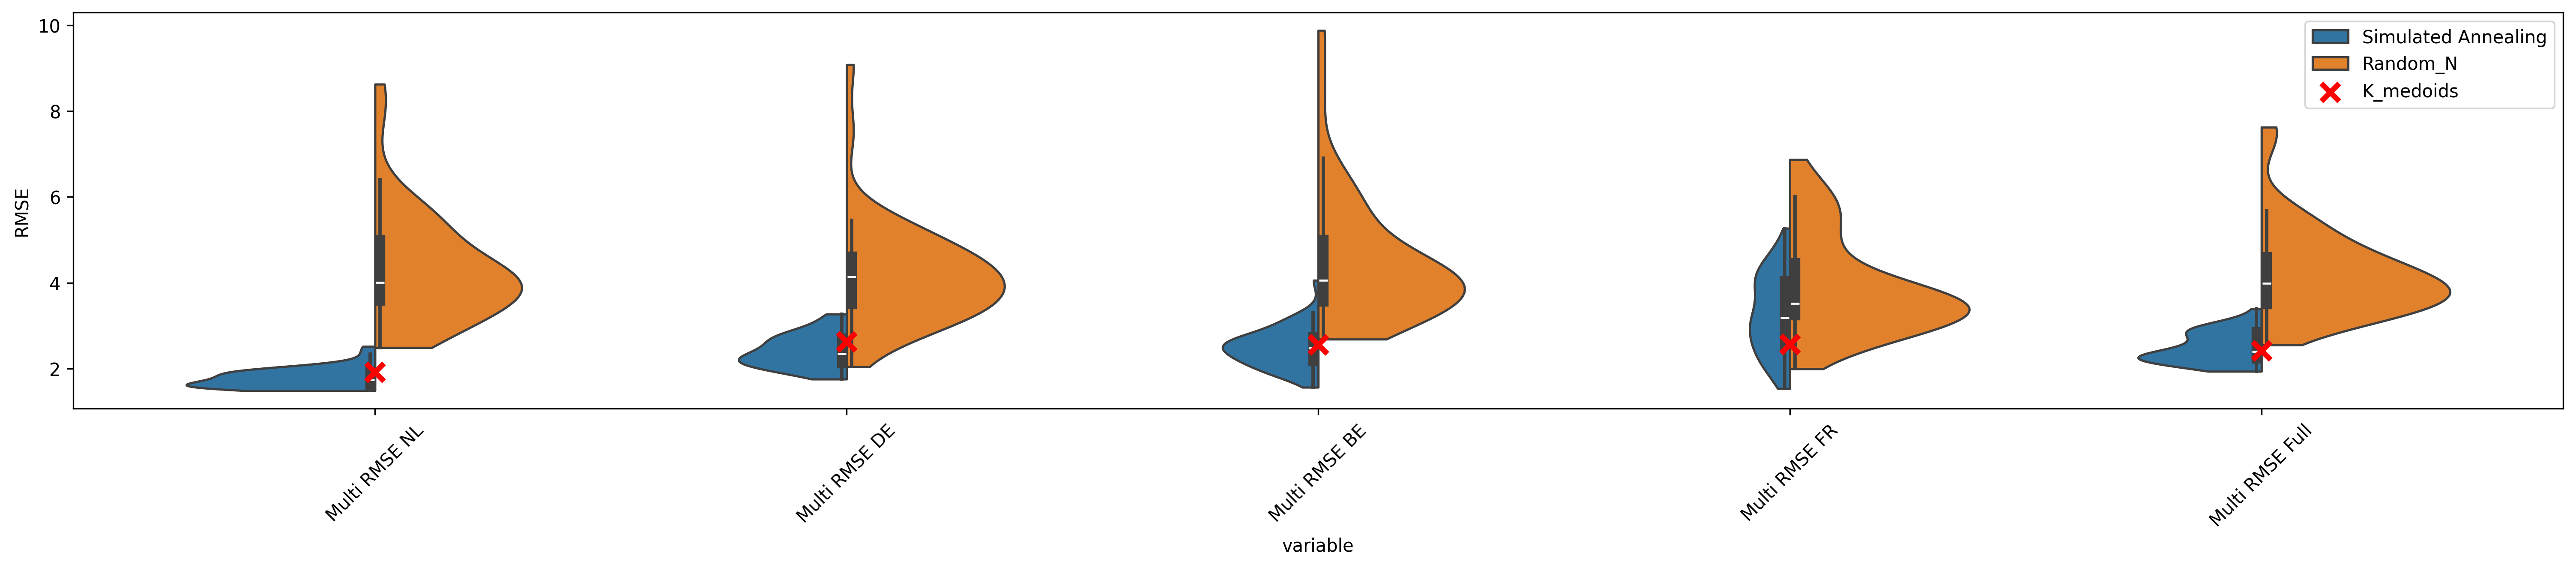

In [79]:
# violin plot comparing main SA vs random draw

fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_sa_random,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_metrics[df_metrics["dataset"] == "K_medoids_load"]
for i, country in enumerate(COUNTRIES):
    k_medoids_rmse = k_medoids_metrics[
        k_medoids_metrics["variable"] == f"Multi RMSE {country}"
    ]["RMSE"].iloc[0]
    ax.scatter(
        i,
        k_medoids_rmse,
        marker="x",
        color="red",
        s=100,
        linewidth=3,
        label="K_medoids" if i == 0 else "",
        zorder=10,
    )

ax.scatter(
    i + 1,
    k_medoids_metrics[k_medoids_metrics["variable"] == "Multi RMSE Full"]["RMSE"].iloc[
        0
    ],
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    zorder=10,
)

ax.tick_params(axis="x", labelrotation=45)
ax.set_ylabel("RMSE")
ax.legend()

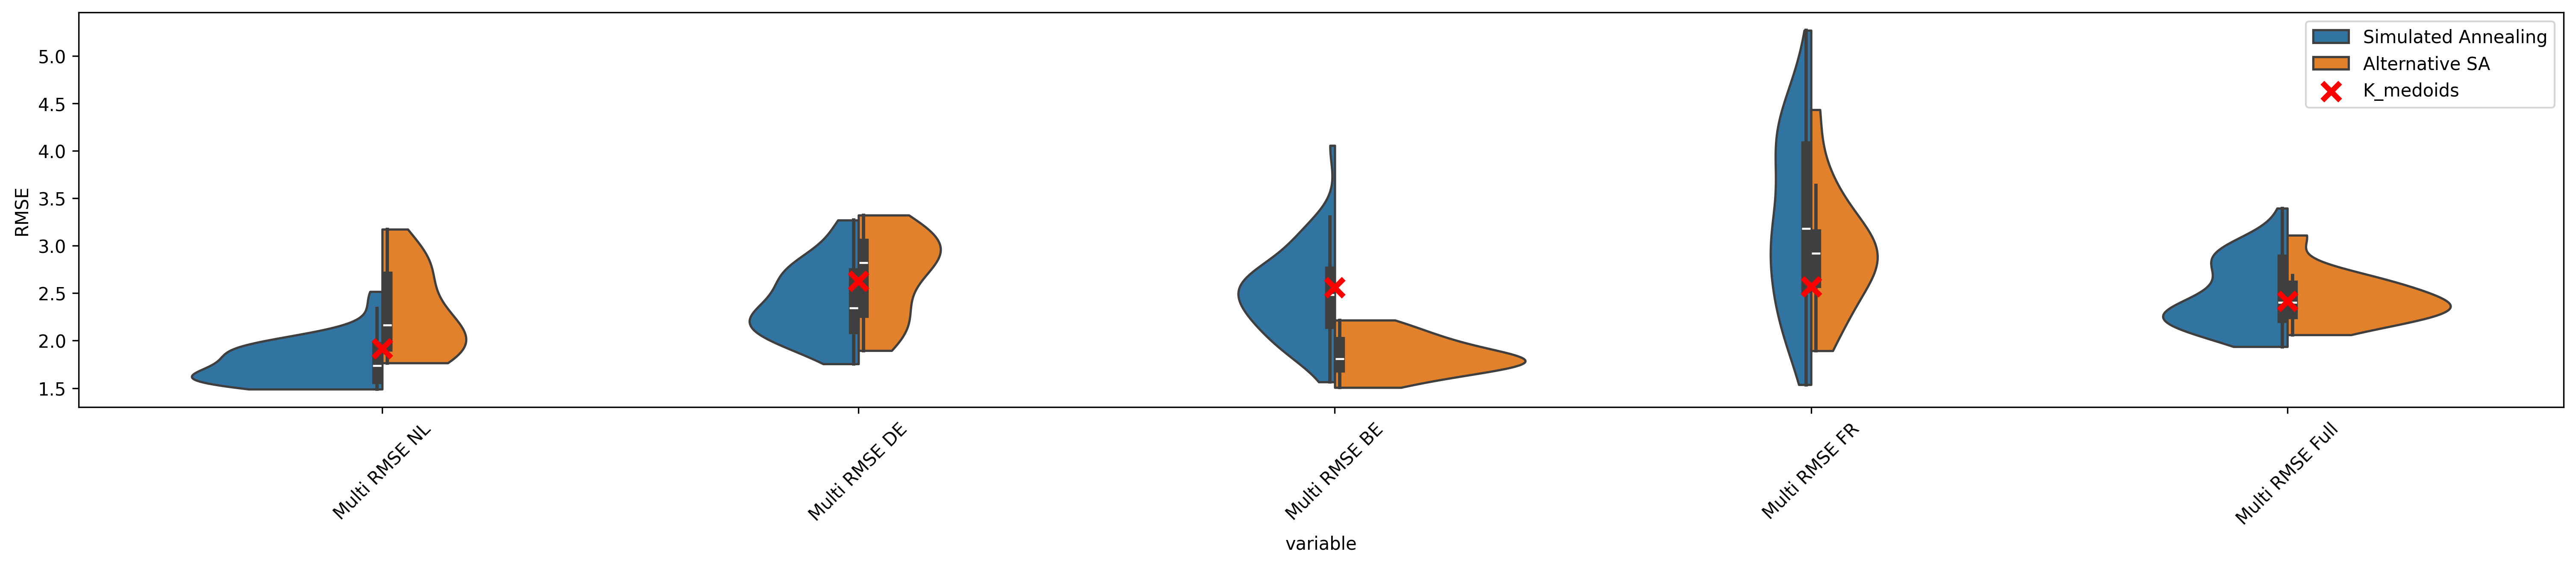

In [80]:
# violin with comparing two SA versions

fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_sa,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_metrics[df_metrics["dataset"] == "K_medoids_load"]

for i, country in enumerate(COUNTRIES):
    k_medoids_rmse = k_medoids_metrics[
        k_medoids_metrics["variable"] == f"Multi RMSE {country}"
    ]["RMSE"].iloc[0]
    ax.scatter(
        i,
        k_medoids_rmse,
        marker="x",
        color="red",
        s=100,
        linewidth=3,
        label="K_medoids" if i == 0 else "",
        zorder=10,
    )


ax.scatter(
    i + 1,
    k_medoids_metrics[k_medoids_metrics["variable"] == "Multi RMSE Full"]["RMSE"].iloc[
        0
    ],
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    zorder=10,
)


ax.tick_params(axis="x", labelrotation=45)
ax.set_ylabel("RMSE")
ax.legend()

## 4.2 Univariate comparison

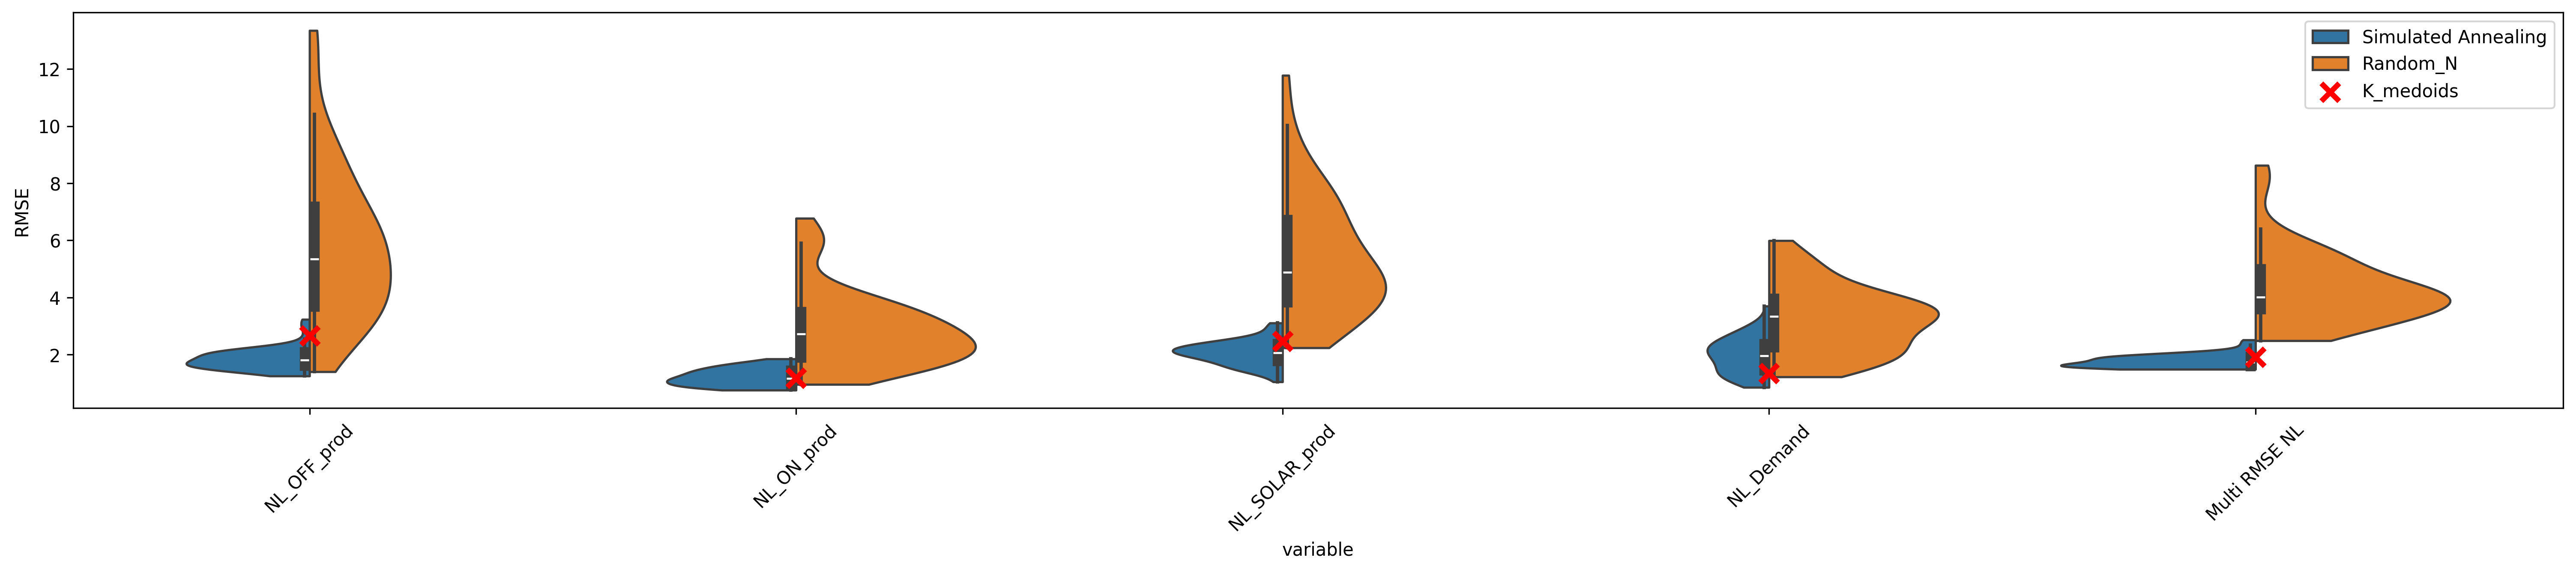

In [81]:
# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_uni,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_metrics[df_metrics["dataset"] == "K_medoids_load"].query(
    "variable in @plot_vars"
)

for i, var in enumerate(plot_vars):
    k_medoids_rmse = k_medoids_metrics[k_medoids_metrics["variable"] == var][
        "RMSE"
    ].iloc[0]
    ax.scatter(
        i,
        k_medoids_rmse,
        marker="x",
        color="red",
        s=100,
        linewidth=3,
        label="K_medoids" if i == 0 else "",
        zorder=10,
    )
    # random_large_rmse = df_metrics_with_multi[df_metrics_with_multi['dataset'] == 'Large Random'][df_metrics_with_multi['variable'] == var]['RMSE'].iloc[0]
    # ax.scatter(i, random_large_rmse, marker='x', color='blue', s=100, linewidth=3, label='Large Random' if i == 0 else "", zorder = 10)

ax.tick_params(axis="x", labelrotation=45)
# ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

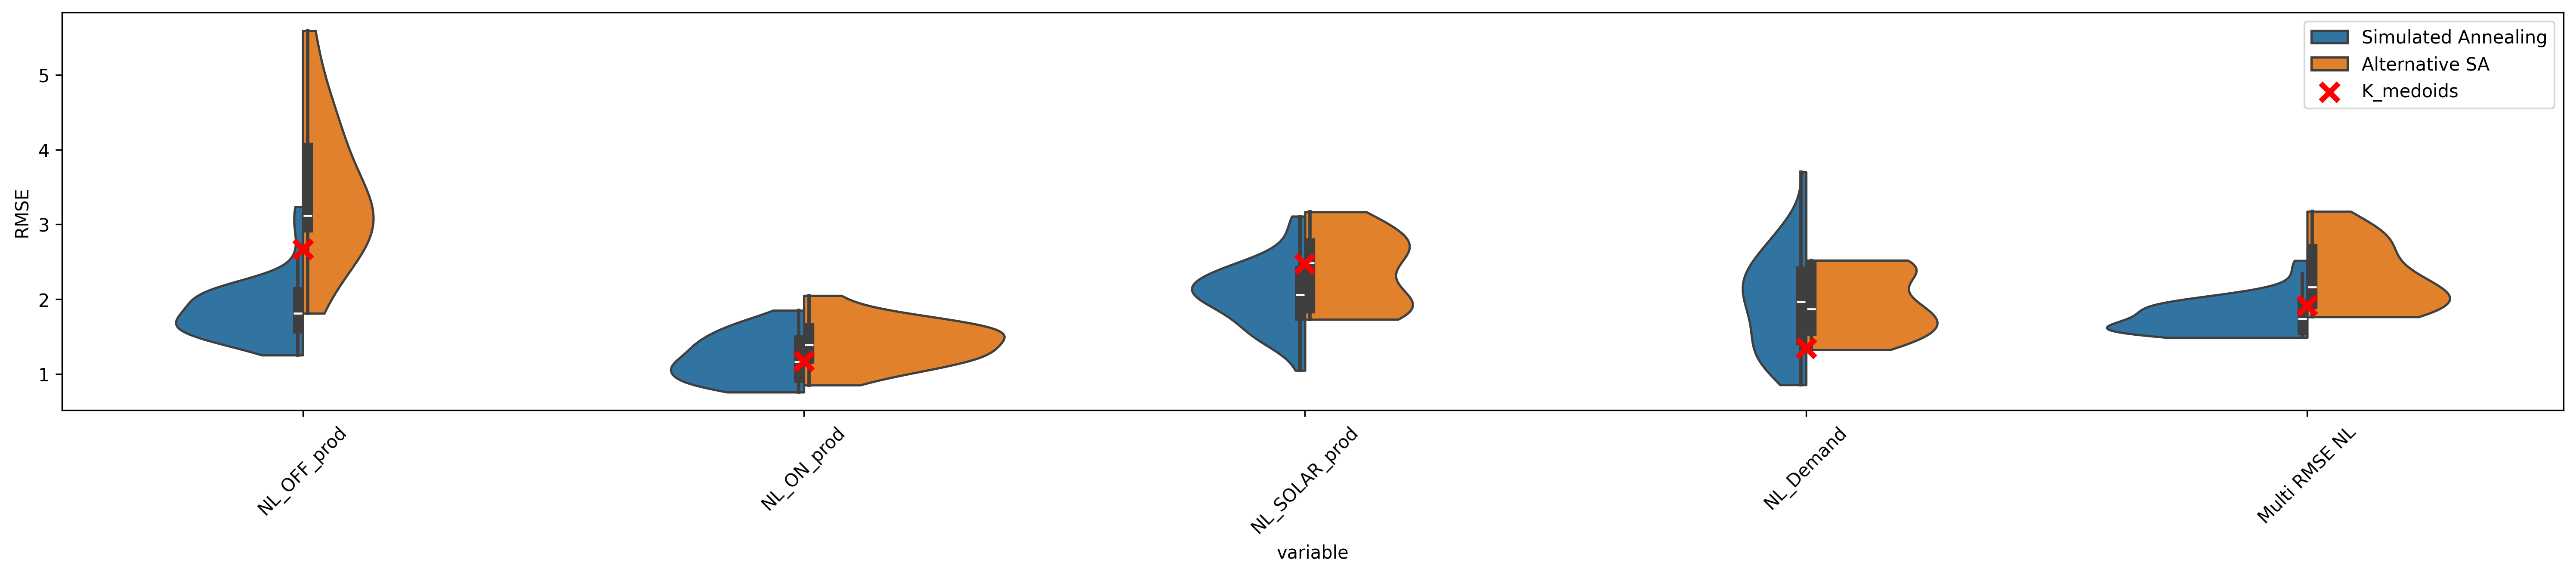

In [82]:
# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_uni_sa,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_metrics[df_metrics["dataset"] == "K_medoids_load"].query(
    "variable in @plot_vars"
)

for i, var in enumerate(plot_vars):
    k_medoids_rmse = k_medoids_metrics[k_medoids_metrics["variable"] == var][
        "RMSE"
    ].iloc[0]
    ax.scatter(
        i,
        k_medoids_rmse,
        marker="x",
        color="red",
        s=100,
        linewidth=3,
        label="K_medoids" if i == 0 else "",
        zorder=10,
    )

ax.tick_params(axis="x", labelrotation=45)
ax.set_ylabel("RMSE")
ax.legend()

## 4.3 Wasserstein comparison

(0.0, 10.0)

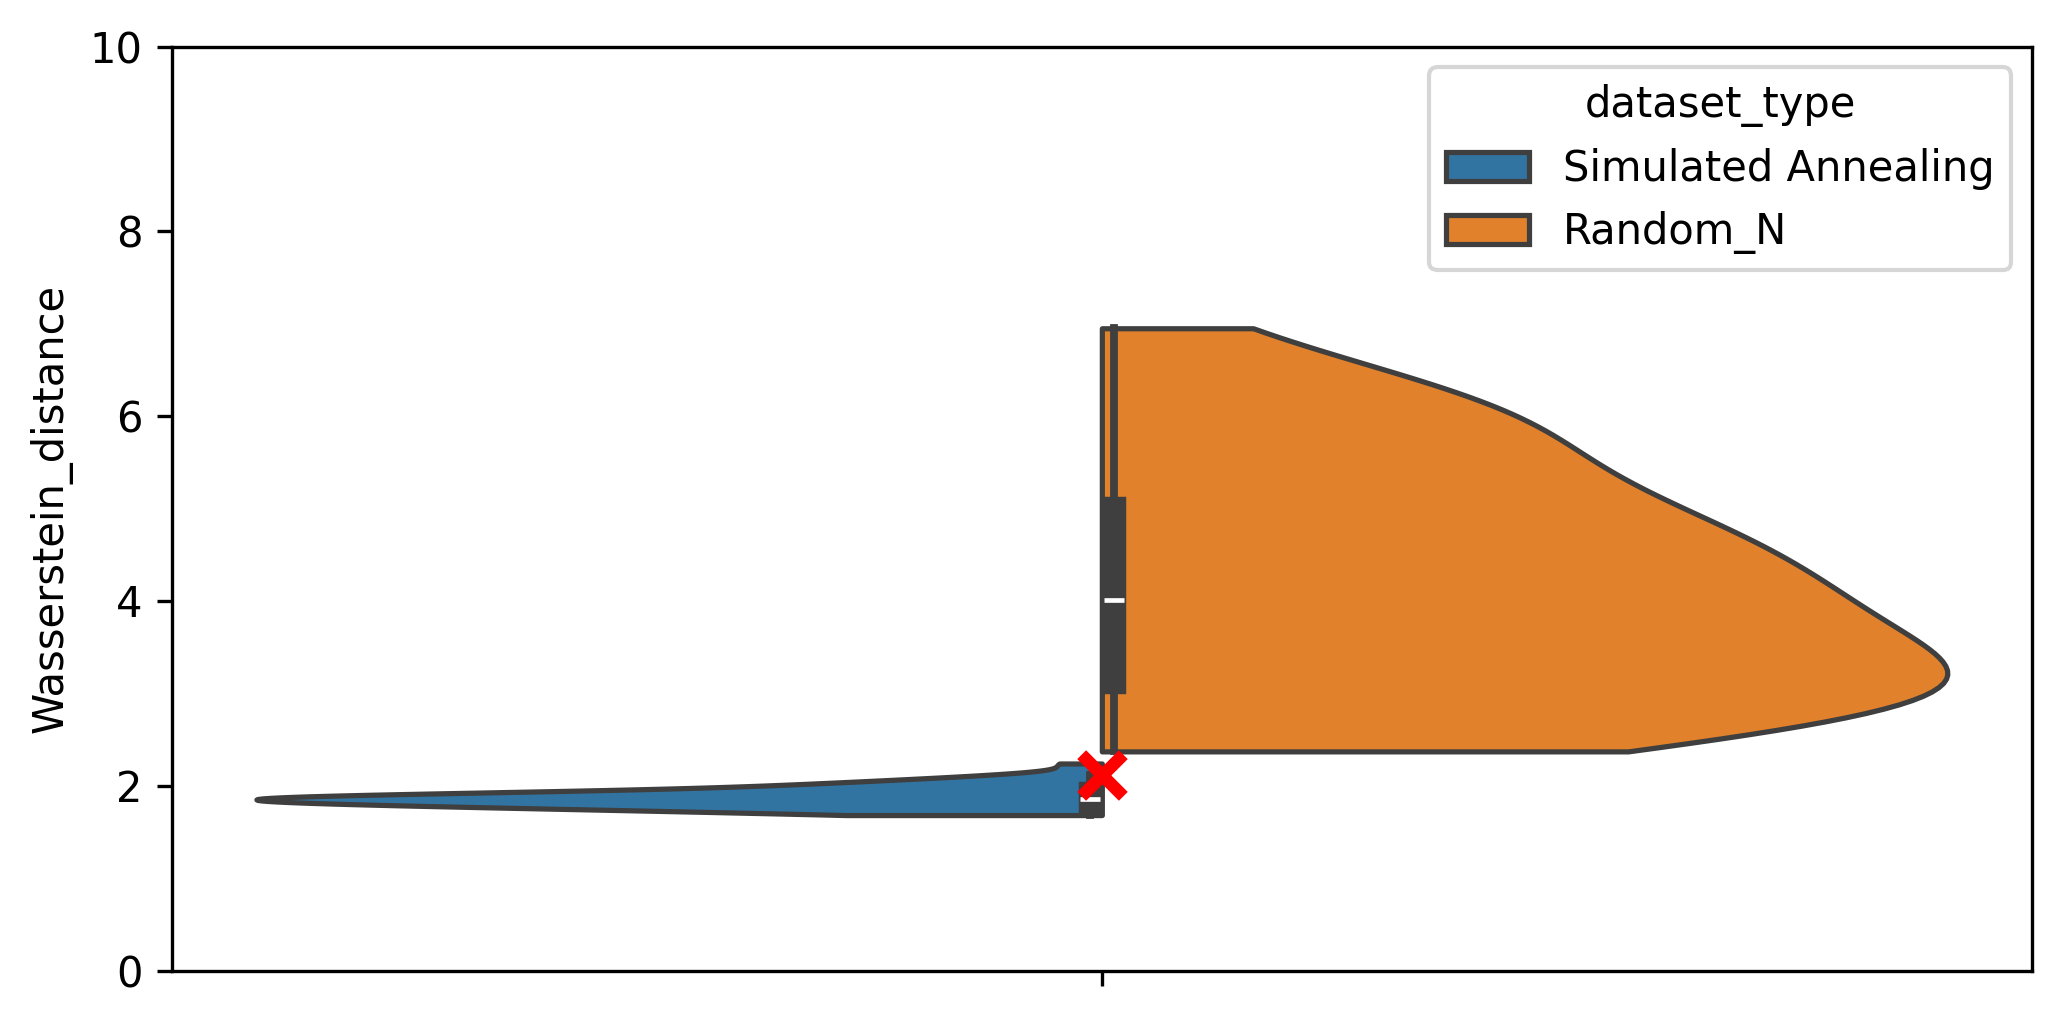

In [ ]:
# main SA vs random

fig, ax = plt.subplots(figsize=(8, 4), dpi=300)
# Create violin plot with split violins
sns.violinplot(
    data=violin_data_wasserstein,
    hue="dataset_type",
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)
# Add K_medoids RMSE as scatter points
k_medoids_wasserstein = df_wasserstein.loc["K_medoids_load", "Wasserstein_distance"]
ax.scatter(
    0,
    k_medoids_wasserstein,
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    label="K_medoids",
    zorder=10,
)

ax.set_ylim(0, 10)

(0.0, 10.0)

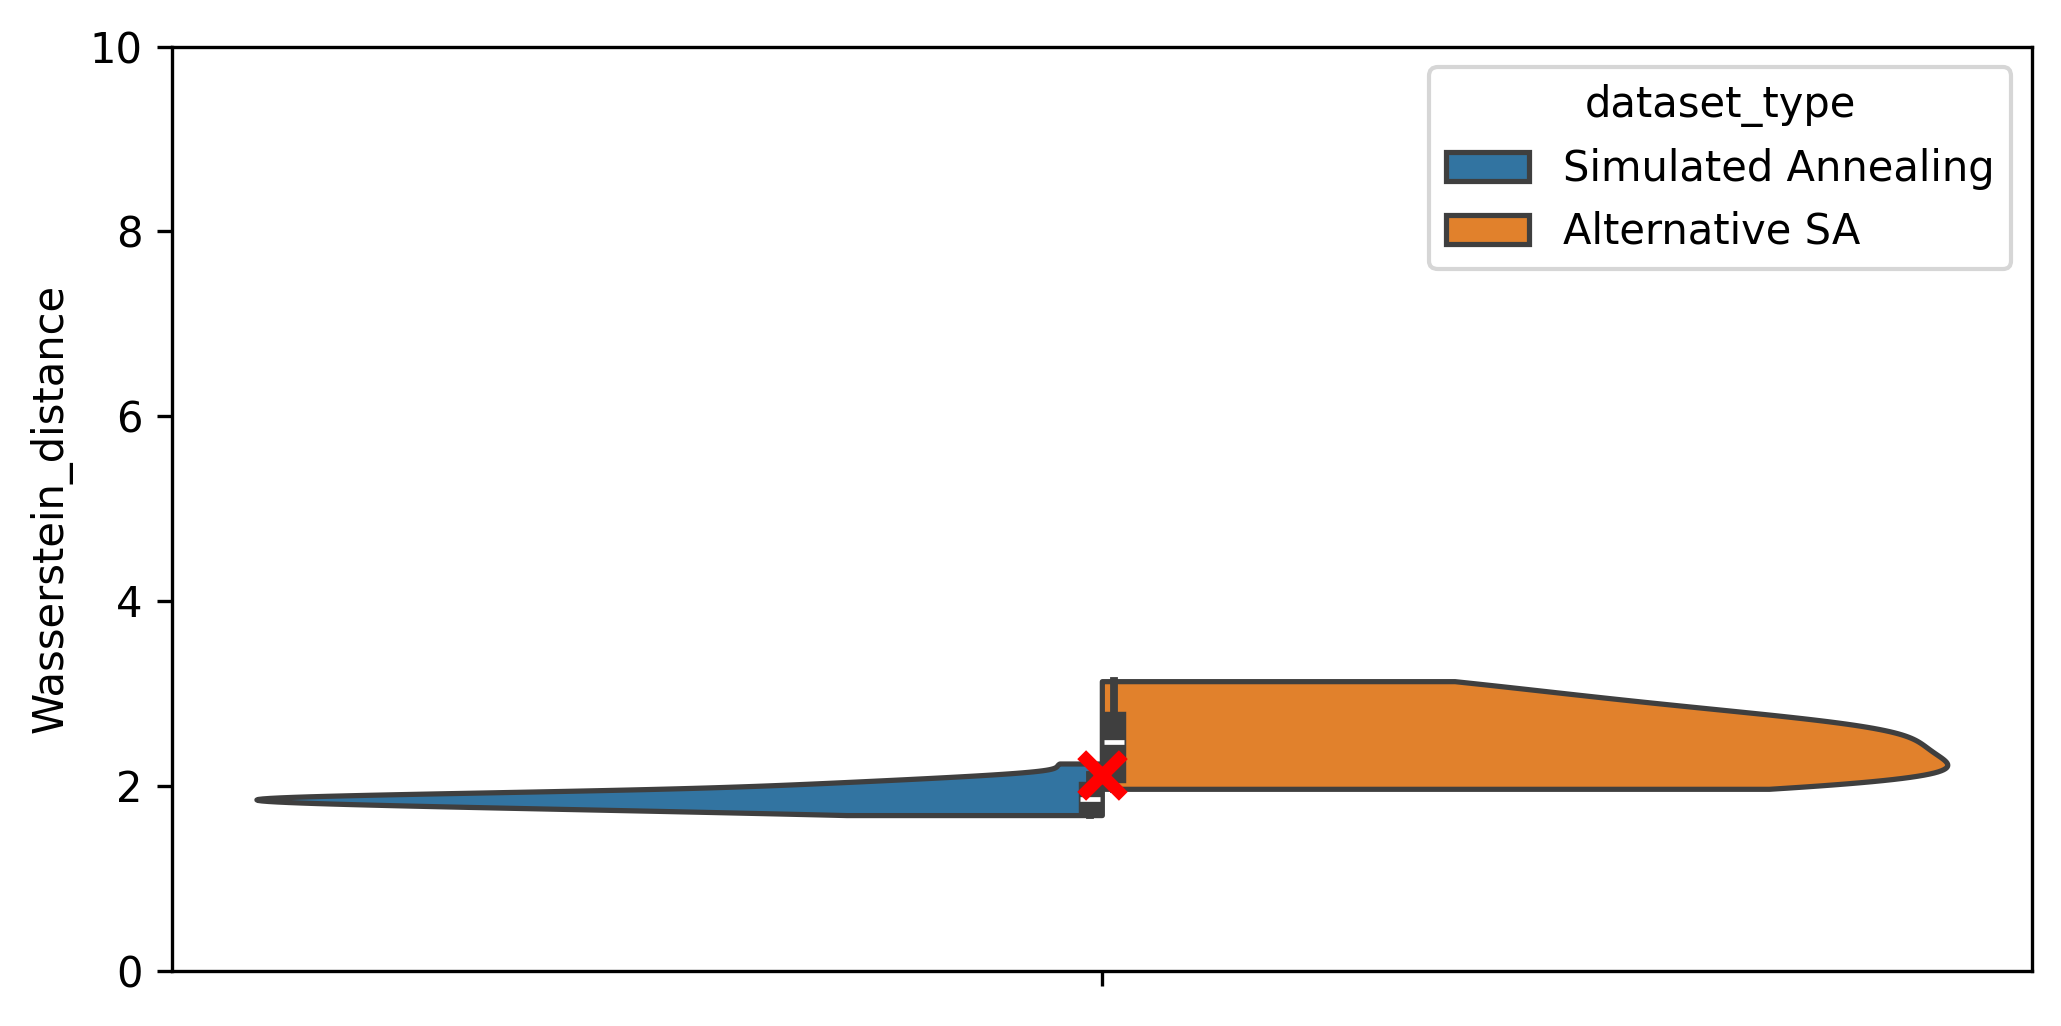

In [ ]:
# main SA vs alternative SA
fig, ax = plt.subplots(figsize=(8, 4), dpi=300)
# Create violin plot with split violins
sns.violinplot(
    data=violin_data_wasserstein_sa,
    hue="dataset_type",
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)
# Add K_medoids RMSE as scatter points
k_medoids_wasserstein = df_wasserstein.loc["K_medoids_load", "Wasserstein_distance"]
ax.scatter(
    0,
    k_medoids_wasserstein,
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    label="K_medoids",
    zorder=10,
)

ax.set_ylim(0, 10)

## 4.4 Look at impact of subset size

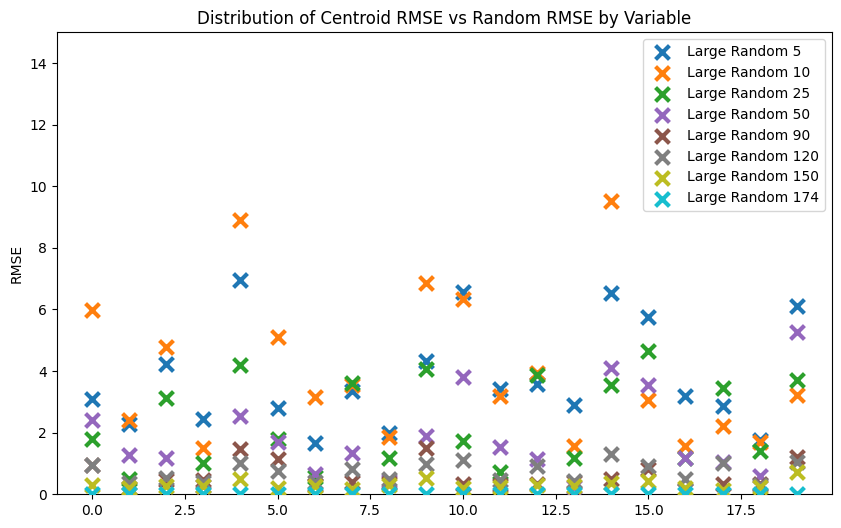

In [83]:
# calculate large random scores

# Get centroid RMSE values for each variable
random_metrics_lr = df_metrics.query("dataset.str.contains('Large Random')")

# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.tab10(np.linspace(0, 1, len(sizes)))
for i, var in enumerate(all_vars):
    for j, size in enumerate(sizes):
        rmse = random_metrics_lr.query(
            f"dataset == 'Large Random {size}' and variable == @var"
        )["RMSE"].item()
        ax.scatter(
            i,
            rmse,
            marker="x",
            s=100,
            linewidth=3,
            label=f"Large Random {size}" if i == 0 else "",
            zorder=10,
            color=colors[j],
        )

ax.set_ylim(0, 15)
ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

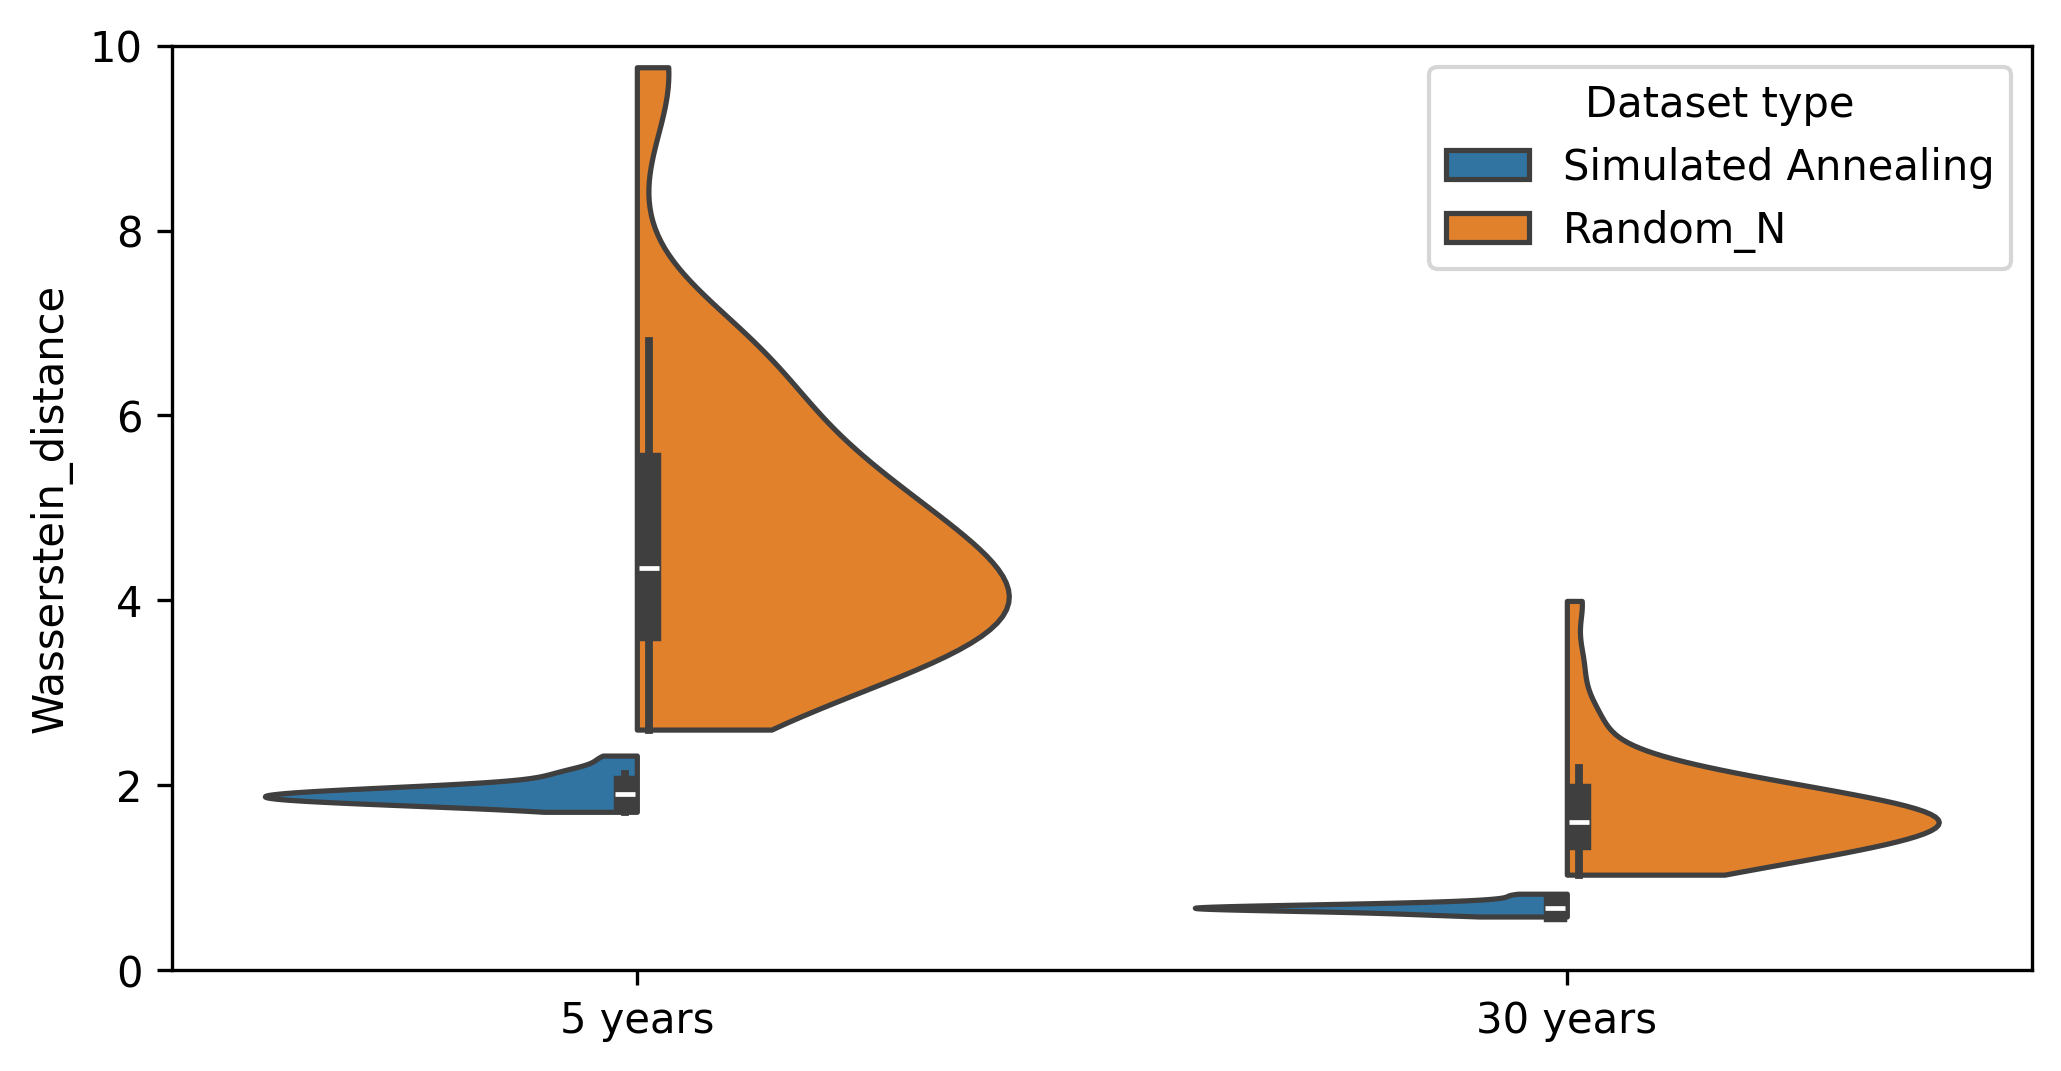

In [107]:
# main SA vs large/small SA
fig, ax = plt.subplots(figsize=(8, 4), dpi=300)

sns.violinplot(
    data=violin_data_wasserstein,
    hue="dataset_type",
    x=1,
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)

handles, labels = ax.get_legend_handles_labels()

sns.violinplot(
    data=violin_data_wasserstein_large_small,
    hue="dataset_type",
    x=0,
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)

# Use only the legend from the first plot
ax.legend(handles, labels, title="Dataset type")

ax.set_ylim(0, 10)
ax.set_xticks([0, 1], ["5 years", "30 years"])